# Execution Algorithm Research — SET50 (hourly)

**คำถามวิจัย:** ถ้าใช้ *parent order ชุดเดียวกัน* algo แต่ละตัวเสียต้นทุน execution ต่างกันเท่าไหร่ และผลนี้ขึ้นกับขนาด order, ช่วงเวลาของวัน, volatility และปีแค่ไหน

algo ที่เทียบ: **MARKET, TWAP, VWAP, POV10, POV5, POV5/10** (POV5/10 = 5% ช่วงเช้า / 10% ช่วงบ่าย)

**สมมติฐานที่ทดสอบ**
1. **H1** order ยิ่งใหญ่เมื่อเทียบกับ ADV algo ที่ทยอยส่งจะยิ่งถูกกว่า MARKET เพราะ impact เพิ่มตาม √ขนาด
2. **H2** VWAP ถูกกว่า TWAP เพราะส่งหนักในชั่วโมงที่ตลาดซื้อขายมาก
3. **H3** algo ที่ทยอยส่งแลกต้นทุนที่ต่ำลงด้วยความเสี่ยงที่สูงขึ้น (std ของ IS)
4. **H4** POV ที่ rate ต่ำกว่าเสีย impact น้อยกว่า แต่เสี่ยงทำไม่เสร็จ และการแบ่ง rate ตามช่วงเช้า/บ่ายช่วยลดต้นทุนได้

ทุกค่าที่ปรับได้อยู่ใน `src/constants.py` การทดลองทั้งหมดรันผ่าน `src/experiment.run_experiment()` ตัวเดียวกับ `run.py`

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
from src import constants as C, plots
from src.experiment import run_experiment

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plots.style()
ex = run_experiment()                      # ~15 s: main run + sensitivity
mk, summ = ex["market"], ex["summary"]

## 1. ข้อมูลและการเตรียมข้อมูล

* ไฟล์ `SET50_2023–2026.csv` แท่งรายชั่วโมง มี OHLC, `TRADING_VALUE` (บาท) และ `TRADING_VOLUME` (หุ้น)
* **Universe lock 10 ตัวตลอดช่วง:** KBANK, CPALL, ADVANC, PTTEP, AOT, BBL, SCB, PTT, KTB, BDMS ทุกตัวสภาพคล่องสูง ข้อมูลครบตั้งแต่ ม.ค. 2023 และไม่มีราคากระโดดจาก corporate action ที่ยังไม่ได้ปรับ
* เก็บแท่ง **10, 11, 12, 13, 14, 15, 16, 17** ได้ 8 แท่งต่อวัน ตัดเฉพาะแถวแปลกๆ นอกเวลา (00/01/09)
* แท่ง 14:00 หายไปราว 30% ของวัน (ทั้งปี 2023) แท่งที่หายจะถูก**เติมเป็นแท่งที่ไม่มีการซื้อขาย** (value = 0, ราคาใช้ค่าล่าสุด) จึง fill ไม่ได้ และไม่ใช้เป็นจุดตัดสินใจ วันที่ขาดแค่แท่ง 14:00 ยังนับเป็นวันครบสำหรับคำนวณ profile (14:00 = 0%)
* **Bar VWAP** = value ÷ volume clip ให้อยู่ในช่วง [low, high] ใช้เป็นราคา fill
* **VWAP profile แบบ rolling:** ณ วัน d ใช้สัดส่วนมูลค่าซื้อขายรายชั่วโมง เฉลี่ยรวมทั้ง 10 ตัว ของ **21 วันเทรดก่อนหน้า** (ไม่นับวัน d จึงไม่มี look-ahead) backtest จึงเริ่มได้ตั้งแต่ ก.พ. 2023 ยาวราว **3.8 ปี**
* **ADV** = มูลค่าซื้อขายเฉลี่ยต่อวันของ 20 วันก่อนหน้า ใช้รายงานว่า order ใหญ่แค่ไหนเมื่อเทียบกับตลาด

,data
files,"[SET50_2023.csv, SET50_2024.csv, SET50_2025.cs..."
rows_raw,343633
rows_off_grid,50
bars,7536
bars_inserted_empty,323
inserted_by_hour,"{10: 5, 11: 2, 12: 2, 13: 3, 14: 305, 15: 2, 1..."
tickers,"[KBANK, CPALL, ADVANC, PTTEP, AOT, BBL, SCB, P..."
start,2023-01-03 10:00:00
end,2026-11-19 17:00:00
jump_bars,0


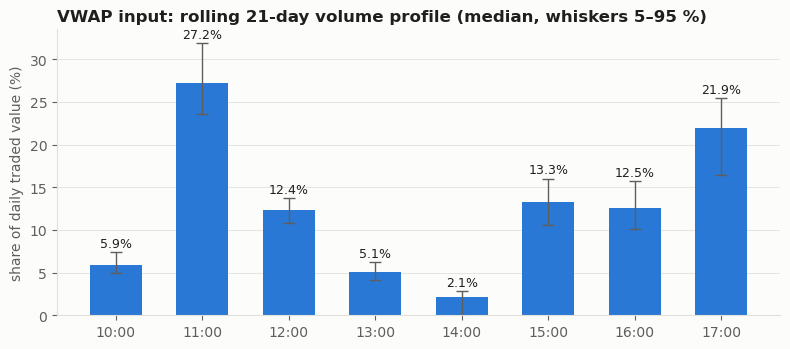

hour,10,11,12,13,14,15,16,17
5%,4.98,23.64,10.82,4.16,0.00,10.53,10.13,16.44
50%,5.94,27.19,12.36,5.10,2.13,13.29,12.54,21.94
95%,7.40,31.92,13.77,6.25,2.84,16.03,15.71,25.45


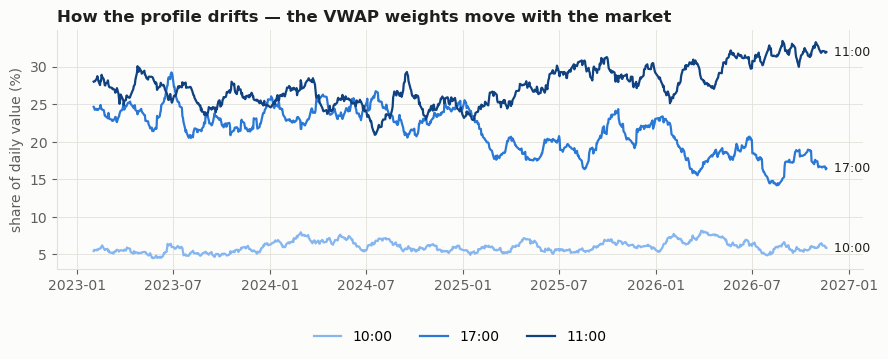

In [2]:
display(pd.Series(mk.info, name="data").to_frame())
plots.volume_profile(mk.profile); plt.show()
display((mk.profile.dropna().describe(percentiles=[.05, .5, .95]).loc[["5%", "50%", "95%"]] * 100))
plots.profile_over_time(mk.profile); plt.show()

## 2. Market model และ cost model

ทุก child order fill ที่ **VWAP ของแท่งที่ fill** และจ่ายต้นทุนดังนี้

| ส่วน | สูตร | หมายเหตุ |
|---|---|---|
| ½ spread | `SPREAD_TICKS × tick(price) / 2` | **ค่าสมมติ** 1 tick เพราะไม่มี bid/ask (sensitivity ที่ 2 tick) |
| impact | `Y × σ_hour × √(child ÷ มูลค่าซื้อขายของแท่ง) × price` | square-root law, Y = 1 (sensitivity 0.5, 2), σ ex-ante 100 แท่ง |
| commission | 0.157% × (1 + VAT 7%) | |

กติกาการ fill
* ตัดสินใจและตั้ง arrival ที่ Close_t แล้ว child แรกเริ่มที่แท่ง t+1
* แท่งที่ไม่มีการซื้อขาย fill ไม่ได้
* impact เป็นแบบชั่วคราว ไม่สะสมข้ามแท่ง

## 3. ออกแบบการทดลอง — parent order

1. สุ่ม **2,000 ชุด** ของ (แท่งที่ตัดสินใจ, หุ้น, ฝั่งซื้อ/ขาย) ตลอดช่วง **ก.พ. 2023 → พ.ย. 2026** สุ่มหุ้นจาก 10 ตัวที่ lock ไว้
2. แต่ละชุดใช้ **ทั้ง 4 ขนาด** คือ 1%, 5%, 10% และ 25% ของ NAV 100M ได้ทั้งหมด **8,000 order** ผลของขนาดจึงวัดบนเวลา หุ้น และฝั่งเดียวกันทุกประการ
3. **ทุก algo execute order ชุดเดียวกัน** การเทียบจึงเป็นแบบ paired
4. ฝั่งขายถือว่ามีหุ้นอยู่แล้ว ไม่มีข้อจำกัดเรื่องพอร์ตหรือเงินสด

In [3]:
od = ex["orders"]
print(ex["orders_info"])
display(od.groupby("bucket", sort=False).agg(n=("order_id", "size"), notional_M=("paper_notional", lambda s: s.mean() / 1e6),
        pct_adv_median=("pct_adv", lambda s: s.median() * 100), pct_adv_p95=("pct_adv", lambda s: s.quantile(.95) * 100))
        .sort_values("notional_M"))
base = od.drop_duplicates("base_id")
display(pd.concat([base.groupby("ticker").size().rename("draws"), base.groupby("year").size().rename("draws")]).to_frame().T)

{'n_base': 2000, 'n_orders': 8000, 'rejected_draws': {'not_observed': 75, 'jump': 0, 'no_price': 0, 'no_sigma': 0}, 'first_decision_allowed': '2023-02-01 10:00:00', 'last_decision_allowed': '2026-11-18 17:00:00'}


,n,notional_M,pct_adv_median,pct_adv_p95
bucket,,,,
1% NAV,2000,0.99,0.07,0.13
5% NAV,2000,4.99,0.36,0.67
10% NAV,2000,9.99,0.72,1.33
25% NAV,2000,25.00,1.81,3.33


,ADVANC,AOT,BBL,BDMS,CPALL,KBANK,KTB,PTT,PTTEP,SCB,2023,2024,2025,2026
draws,190,210,200,202,211,196,221,192,198,180,453,509,537,501


## 4. Algorithm ทั้ง 6 ตัว (horizon = 8 แท่ง = 1 วันเทรด, เริ่มที่ t+1)

| Algo | ต้องการส่งเท่าไหร่ในแท่ง t+1+k | cap ต่อแท่ง | ถ้าไม่เสร็จ |
|---|---|---|---|
| **MARKET** | ที่เหลือทั้งหมด (แท่งแรกที่มีการซื้อขาย) | ไม่มี cap จ่าย impact เต็ม | — |
| **TWAP** | เป้าสะสม Q·(k+1)/8 | 25% ของมูลค่าในแท่ง | ตามเก็บในแท่งถัดไป ครบ horizon แล้ว cancel |
| **VWAP** | เป้าสะสมตาม rolling profile ของวันที่ตัดสินใจ | 25% ของมูลค่าในแท่ง | เหมือน TWAP |
| **POV10** | 10% × มูลค่าซื้อขายจริงของแท่ง | rate คือ cap ในตัว | ครบ horizon แล้ว cancel |
| **POV5** | 5% × มูลค่าซื้อขายจริงของแท่ง | rate คือ cap ในตัว | ครบ horizon แล้ว cancel |
| **POV5/10** | 5% ในแท่ง 10–13 (เช้า) / 10% ในแท่ง 14–17 (บ่าย) แบ่งตรงช่วงพักเที่ยง 12:30–14:30 | rate คือ cap ในตัว | ครบ horizon แล้ว cancel |

ส่วนที่ cancel คิดเป็น **opportunity cost** ที่ Close_{t+8}

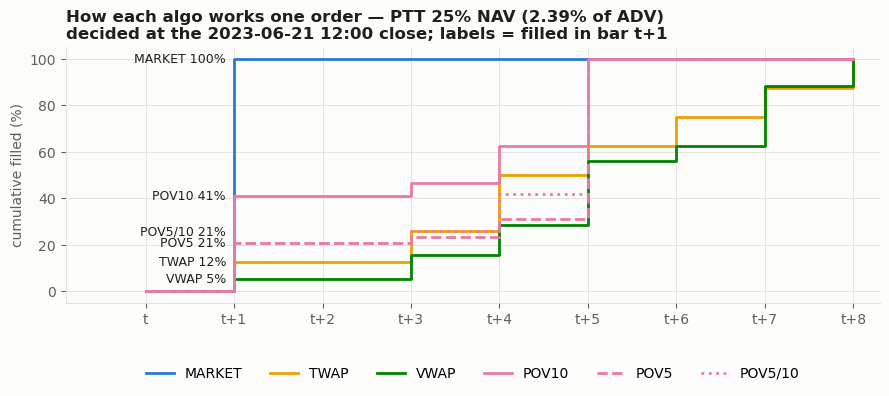

,algo,datetime,qty,bar_vwap,bar_value,participation,impact,exec_price
54277,MARKET,2023-06-21 13:00:00,793600,31.73,"103,508,875.00",0.24,0.15,31.46
54278,TWAP,2023-06-21 13:00:00,99200,31.73,"103,508,875.00",0.03,0.05,31.55
54279,TWAP,2023-06-21 15:00:00,106100,31.70,"13,454,775.00",0.25,0.15,31.43
54280,TWAP,2023-06-21 16:00:00,191500,31.64,"40,146,225.00",0.15,0.11,31.40
54281,TWAP,2023-06-21 17:00:00,99200,31.73,"371,143,325.00",0.01,0.03,31.58
54282,TWAP,2023-06-22 10:00:00,99200,31.76,"75,662,250.00",0.04,0.06,31.57
54283,TWAP,2023-06-22 11:00:00,99200,31.76,"256,115,300.00",0.01,0.03,31.60
54284,TWAP,2023-06-22 12:00:00,99200,31.77,"47,225,525.00",0.07,0.08,31.57
54285,VWAP,2023-06-21 13:00:00,40700,31.73,"103,508,875.00",0.01,0.03,31.57
54286,VWAP,2023-06-21 15:00:00,82200,31.70,"13,454,775.00",0.19,0.13,31.45


In [4]:
res, fills = ex["results"], ex["fills"]
pick = od[(od.bucket == "25% NAV") & (od.hour == 12)].sort_values("pct_adv").iloc[200]
plots.example_schedule(fills, pick); plt.show()
display(fills[fills.order_id == pick.order_id][["algo", "datetime", "qty", "bar_vwap", "bar_value", "participation", "impact", "exec_price"]])

## 5–6. Simulation engine, benchmark และ metric

* `src/engine.py` ทำงานทีละแท่ง โดยทุก algo ใช้เส้นทาง fill และ cost เดียวกัน ต่างกันแค่จำนวนที่อยากส่งในแต่ละแท่ง
* **Implementation Shortfall (IS)** เทียบกับ Q × arrival แยกเป็น timing / spread / impact / commission / opportunity
* **vs interval VWAP:** ราคา fill เฉลี่ยเทียบกับ VWAP ของตลาดช่วง t+1 … t+8
* ตัวเลขทั้งหมดเป็น bps และ `is_std` คือ std ของ IS ต่อ order ใช้เป็นตัววัดความเสี่ยง

In [5]:
cols = ["bucket", "algo", "pct_adv_mean", "is_mean", "is_ci_lo", "is_ci_hi", "is_median", "is_std",
        "timing_mean", "spread_mean", "impact_mean", "commission_mean", "opportunity_mean",
        "vs_ivwap_mean", "fully_filled_share", "bars_used_mean", "max_participation_p95"]
t = summ[cols].copy(); t["pct_adv_mean"] *= 100
display(t)

,bucket,algo,pct_adv_mean,is_mean,is_ci_lo,is_ci_hi,is_median,is_std,timing_mean,spread_mean,impact_mean,commission_mean,opportunity_mean,vs_ivwap_mean,fully_filled_share,bars_used_mean,max_participation_p95
0,1% NAV,MARKET,0.08,48.18,45.89,50.39,47.47,49.69,0.57,23.76,7.10,16.74,0.00,30.20,1.00,1.05,0.12
1,1% NAV,TWAP,0.08,44.87,40.94,48.89,43.48,89.08,1.92,23.70,2.55,16.68,0.01,27.05,0.99,7.97,0.04
2,1% NAV,VWAP,0.08,43.84,39.86,47.77,43.97,88.78,1.46,23.70,1.96,16.69,0.01,25.99,0.99,7.97,0.01
3,1% NAV,POV10,0.08,47.54,45.25,49.70,46.85,49.40,0.64,23.76,6.40,16.74,0.00,29.57,1.00,1.12,0.10
4,1% NAV,POV5,0.08,46.85,44.60,48.99,46.18,49.41,0.57,23.76,5.78,16.74,0.00,28.87,1.00,1.21,0.05
5,1% NAV,POV5/10,0.08,47.28,44.99,49.45,46.69,49.44,0.63,23.76,6.14,16.74,0.00,29.30,1.00,1.17,0.08
6,5% NAV,MARKET,0.38,56.98,54.62,59.27,56.32,51.81,0.57,23.76,15.90,16.74,0.00,39.04,1.00,1.05,0.58
7,5% NAV,TWAP,0.38,48.00,44.07,52.01,47.00,88.87,1.93,23.70,5.67,16.68,0.01,30.20,0.99,7.97,0.19
8,5% NAV,VWAP,0.38,46.27,42.35,50.21,46.29,88.45,1.47,23.70,4.39,16.69,0.01,28.44,0.99,7.97,0.07
9,5% NAV,POV10,0.38,51.45,49.17,53.62,50.87,50.17,0.21,23.76,10.74,16.74,0.00,33.49,1.00,1.44,0.10


## 7. ผลลัพธ์
### 7.1 ต้นทุนตามขนาด order (เส้น = ค่าเฉลี่ย, แถบสีจาง = bootstrap 95% CI)

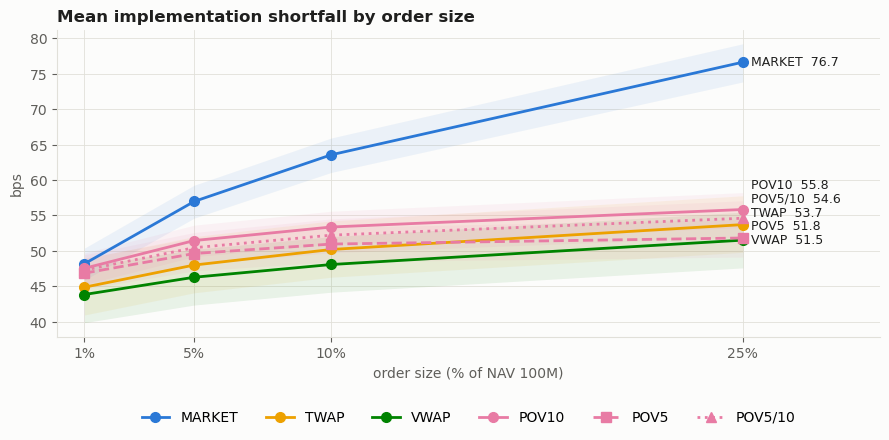

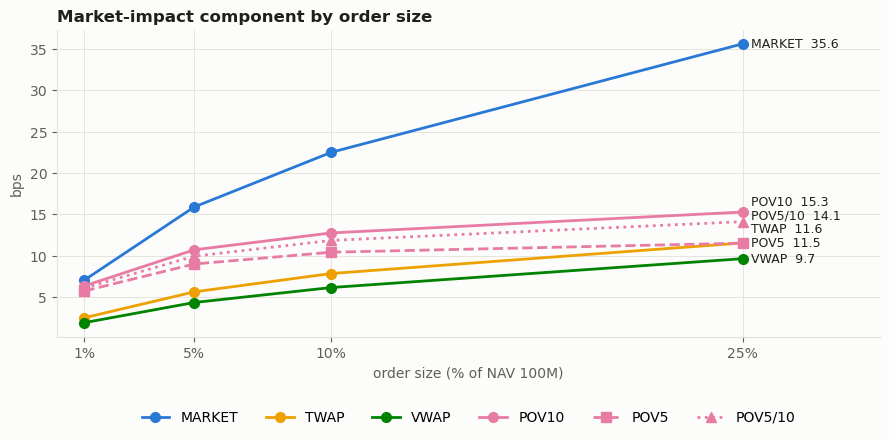

bucket,1% NAV,5% NAV,10% NAV,25% NAV
algo,,,,
MARKET,7.10,15.90,22.50,35.58
TWAP,2.55,5.67,7.89,11.57
VWAP,1.96,4.39,6.20,9.68
POV10,6.40,10.74,12.78,15.30
POV5,5.78,9.03,10.45,11.55
POV5/10,6.14,9.97,11.88,14.14


In [6]:
plots.is_by_size(summ); plt.show()
plots.is_by_size(summ, col="impact_mean", title="Market-impact component by order size", ci=False); plt.show()
display(summ.pivot(index="algo", columns="bucket", values="impact_mean")[sorted(summ.bucket.unique(), key=lambda b: float(b.split("%")[0]))])

**เทียบทุก algo ในแต่ละขนาด order:** แผงบนคือต้นทุนเฉลี่ย (แถบ = 95% CI) แผงล่างคือความเสี่ยง (std ของ IS) ตัวเลขบนแท่งคือค่าที่ดีที่สุดของกลุ่มนั้น POV ทั้ง 3 แบบใช้สีชมพูเดียวกัน แยกด้วยลาย (POV10 ทึบ, POV5 ลายเฉียง, POV5/10 ลายจุด)

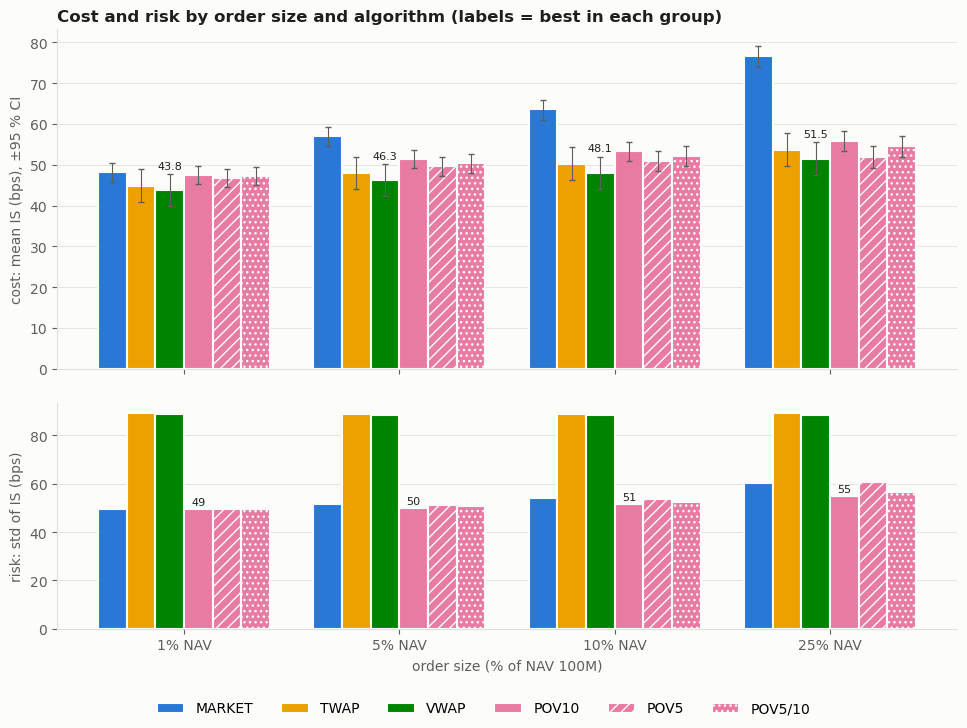

bucket,1% NAV,5% NAV,10% NAV,25% NAV,1% NAV std,5% NAV std,10% NAV std,25% NAV std
algo,,,,,,,,
MARKET,48.18,56.98,63.57,76.65,49.69,51.81,54.16,60.39
TWAP,44.87,48.00,50.20,53.71,89.08,88.87,88.91,89.14
VWAP,43.84,46.27,48.07,51.51,88.78,88.45,88.46,88.54
POV10,47.54,51.45,53.37,55.84,49.40,50.17,51.48,54.86
POV5,46.85,49.62,50.96,51.82,49.41,51.25,53.61,60.80
POV5/10,47.28,50.45,52.22,54.61,49.44,50.90,52.54,56.57


In [7]:
plots.size_algo_bars(summ); plt.show()
cols = sorted(summ.bucket.unique(), key=lambda b: float(b.split("%")[0]))
mean_t = summ.pivot(index="algo", columns="bucket", values="is_mean")[cols]
std_t = summ.pivot(index="algo", columns="bucket", values="is_std")[cols]
display(mean_t.join(std_t, rsuffix=" std"))

### 7.2 Cost–risk frontier
ยิ่งต่ำยิ่งถูก ยิ่งไปซ้ายยิ่งเสี่ยงน้อย

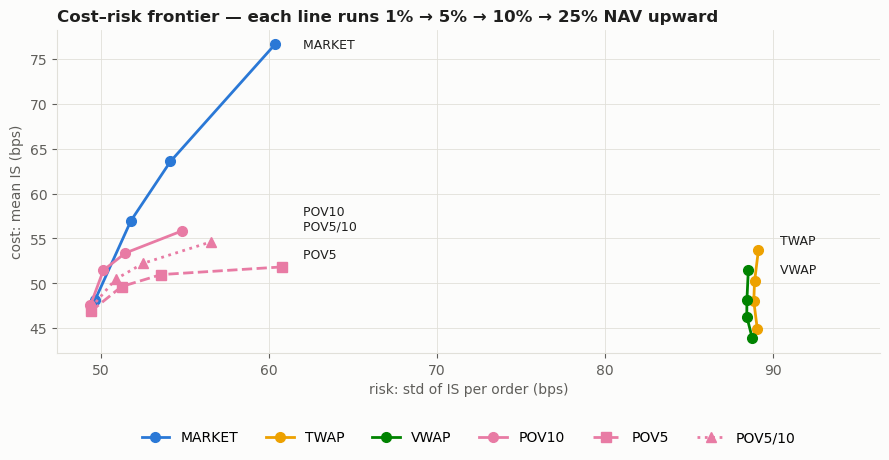

bucket,1% NAV,5% NAV,10% NAV,25% NAV
algo,,,,
MARKET,49.69,51.81,54.16,60.39
TWAP,89.08,88.87,88.91,89.14
VWAP,88.78,88.45,88.46,88.54
POV10,49.40,50.17,51.48,54.86
POV5,49.41,51.25,53.61,60.80
POV5/10,49.44,50.90,52.54,56.57


In [8]:
plots.frontier(summ); plt.show()
display(summ.pivot(index="algo", columns="bucket", values="is_std")[sorted(summ.bucket.unique(), key=lambda b: float(b.split("%")[0]))])

### 7.3 แยกตามชั่วโมงที่ตัดสินใจ และระดับ volatility (order 25% NAV)

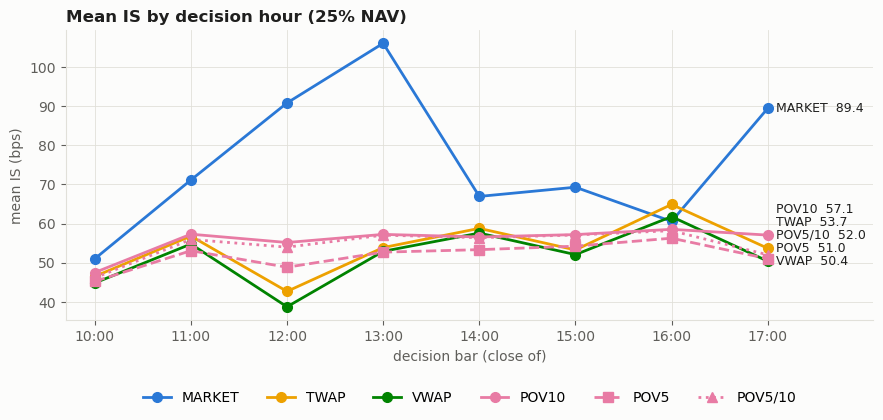

algo,MARKET,TWAP,VWAP,POV10,POV5,POV5/10
hour,,,,,,
10,51.00,46.51,44.82,47.50,45.23,46.13
11,71.14,56.81,54.77,57.30,53.08,55.95
12,90.83,42.68,38.74,55.17,48.86,53.98
13,106.07,53.87,52.92,57.24,52.70,57.05
14,66.95,58.78,57.58,56.58,53.34,56.40
15,69.30,53.27,52.08,57.19,54.23,57.09
16,60.56,64.90,61.78,58.54,56.27,58.19
17,89.44,53.69,50.40,57.06,51.04,52.03


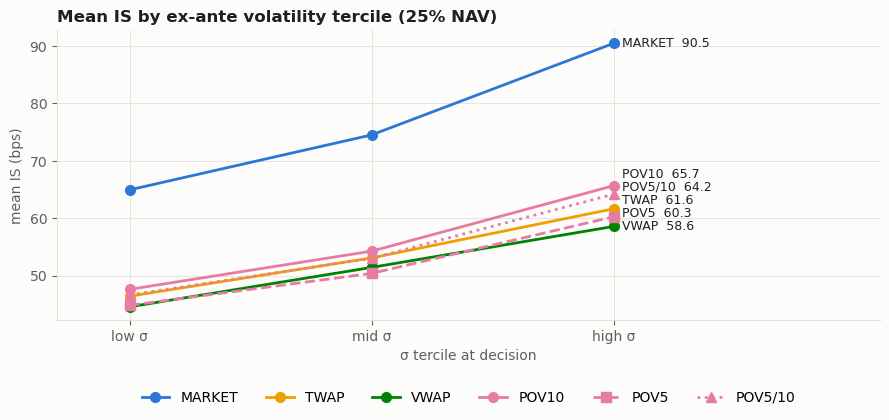

algo                 MARKET  TWAP  VWAP  POV10  POV5  POV5/10
bucket  vol_tercile                                          
1% NAV  low σ         42.76 40.09 38.88  41.95 41.09    41.51
        mid σ         47.49 44.70 44.12  47.01 46.39    46.81
        high σ        54.28 49.81 48.51  53.68 53.07    53.52
5% NAV  low σ         49.62 42.41 40.67  44.48 42.92    43.44
        mid σ         55.85 47.68 46.44  50.76 48.94    49.92
        high σ        65.47 53.90 51.71  59.12 57.01    57.99
10% NAV low σ         54.76 43.99 42.00  45.71 43.93    44.69
        mid σ         62.10 49.76 48.14  52.52 49.88    51.64
        high σ        73.86 56.83 54.08  61.88 59.08    60.32
25% NAV low σ         64.94 46.41 44.55  47.60 44.82    46.63
        mid σ         74.52 53.08 51.42  54.26 50.38    53.01
        high σ        90.49 61.64 58.57  65.67 60.25    64.18

In [9]:
bh, bv = ex["by_hour"], ex["by_vol"]
plots.by_group(bh, "hour", "25% NAV", "Mean IS by decision hour (25% NAV)", "decision bar (close of)"); plt.show()
display(bh[bh.bucket == "25% NAV"].set_index("hour").drop(columns="bucket"))
plots.by_group(bv, "vol_tercile", "25% NAV", "Mean IS by ex-ante volatility tercile (25% NAV)", "σ tercile at decision"); plt.show()
display(bv.set_index(["bucket", "vol_tercile"]))

### 7.4 เทียบ POV ทั้ง 3 แบบ
rate ต่ำลง impact น้อยลง แต่ทำไม่เสร็จบ่อยขึ้น

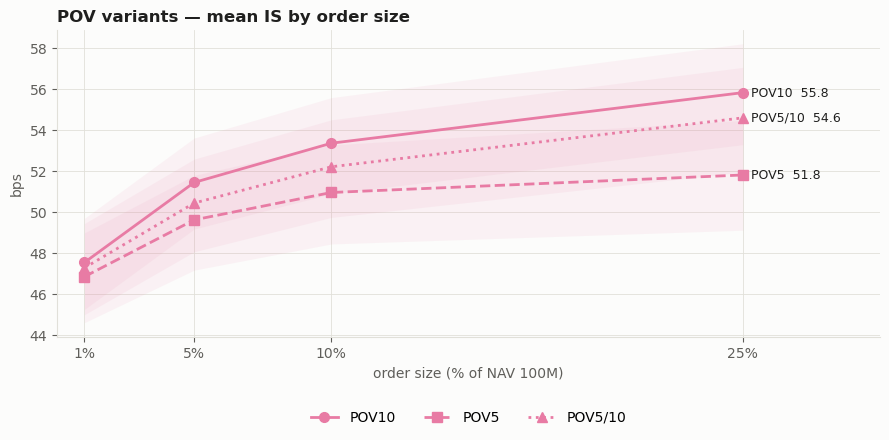

is_mean  is_std  impact_mean  timing_mean  opportunity_mean  fully_filled_share  bars_used_mean
bucket  algo                                                                                                    
1% NAV  POV10      47.54   49.40         6.40         0.64              0.00                1.00            1.12
        POV5       46.85   49.41         5.78         0.57              0.00                1.00            1.21
        POV5/10    47.28   49.44         6.14         0.63              0.00                1.00            1.17
5% NAV  POV10      51.45   50.17        10.74         0.21              0.00                1.00            1.44
        POV5       49.62   51.25         9.03         0.09              0.00                1.00            1.74
        POV5/10    50.45   50.90         9.97        -0.04              0.00                1.00            1.60
10% NAV POV10      53.37   51.48        12.78         0.09              0.00                1.00            1.74
        POV5       50.96   53.61        10.45         0.02              0.00                0.99            2.35
        POV5/10    52.22   52.54        11.88        -0.16              0.00                1.00            2.00
25% NAV POV10      55.84   54.86        15.30         0.07              0.02                0.99            2.65
        POV5       51.82   60.80        11.55         0.25              0.09                0.94            4.10
        POV5/10    54.61   56.57        14.14         0.06              0.05                0.98            3.21

In [10]:
pov = list(C.POV_SCHEDULES)
plots.is_by_size(summ, algos=pov, title="POV variants — mean IS by order size"); plt.show()
display(summ[summ.algo.isin(pov)].set_index(["bucket", "algo"])[["is_mean", "is_std", "impact_mean", "timing_mean",
        "opportunity_mean", "fully_filled_share", "bars_used_mean"]])

## 8. การทดสอบทางสถิติ (paired บน order_id)

`mean_diff` = IS ของ a − IS ของ b (ค่าติดลบ = a ถูกกว่า) มี bootstrap 95% CI ประกอบ
* `t_p_holm` คือ paired t-test ที่ปรับด้วย Holm (15 คู่ต่อ bucket)
* `wilcoxon_p` คือ signed-rank test
* `share_a_cheaper` คือสัดส่วนของ order ที่ a ถูกกว่า b

In [11]:
display(ex["paired"])

,bucket,a,b,n,mean_diff,ci_lo,ci_hi,share_a_cheaper,t_p,wilcoxon_p,t_p_holm,significant
0,1% NAV,MARKET,TWAP,2000,3.31,0.06,6.54,0.48,0.04,0.00,0.21,False
1,1% NAV,MARKET,VWAP,2000,4.34,1.07,7.61,0.48,0.01,0.00,0.06,False
2,1% NAV,MARKET,POV10,2000,0.63,0.41,0.89,0.01,0.00,0.00,0.00,True
3,1% NAV,MARKET,POV5,2000,1.33,0.98,1.69,0.03,0.00,0.00,0.00,True
4,1% NAV,MARKET,POV5/10,2000,0.90,0.60,1.21,0.02,0.00,0.00,0.00,True
5,1% NAV,TWAP,VWAP,2000,1.03,0.49,1.58,0.45,0.00,0.00,0.00,True
6,1% NAV,TWAP,POV10,2000,-2.68,-5.84,0.56,0.52,0.10,0.02,0.29,False
7,1% NAV,TWAP,POV5,2000,-1.98,-5.07,1.21,0.52,0.21,0.05,0.29,False
8,1% NAV,TWAP,POV5/10,2000,-2.41,-5.55,0.82,0.52,0.13,0.02,0.29,False
9,1% NAV,VWAP,POV10,2000,-3.71,-6.93,-0.44,0.52,0.02,0.00,0.15,False


## 9. Sensitivity และ robustness
ปรับทีละพารามิเตอร์ ตัวอื่นคงไว้ที่ค่าหลัก แล้วรันซ้ำบน order 8,000 ตัวเดิม

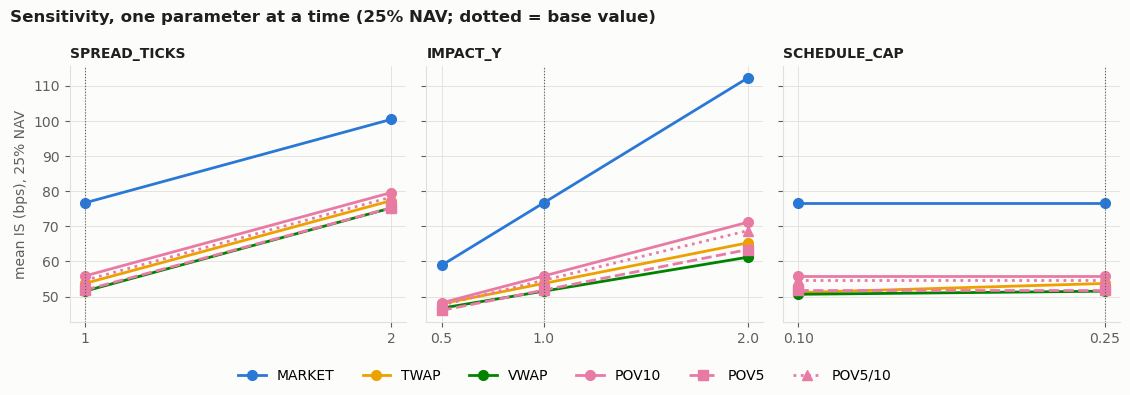

bucket             1% NAV 5% NAV 10% NAV 25% NAV
param        value                              
IMPACT_Y     0.50    VWAP   VWAP    VWAP    POV5
             1.00    VWAP   VWAP    VWAP    VWAP
             2.00    VWAP   VWAP    VWAP    VWAP
SCHEDULE_CAP 0.10    VWAP   VWAP    VWAP    VWAP
             0.25    VWAP   VWAP    VWAP    VWAP
SPREAD_TICKS 1.00    VWAP   VWAP    VWAP    VWAP
             2.00    VWAP   VWAP    VWAP    VWAP

In [12]:
sens = ex["sensitivity"]
plots.sensitivity(sens, "25% NAV"); plt.show()
win = sens[sens["rank"] == 1].pivot_table(index=["param", "value"], columns="bucket", values="algo", aggfunc="first")
display(win[sorted(win.columns, key=lambda b: float(b.split("%")[0]))])

**ผลรายปี:** ถ้าข้อสรุปเป็นจริงทุกปี แปลว่าไม่ได้มาจากสภาพตลาดช่วงใดช่วงหนึ่ง

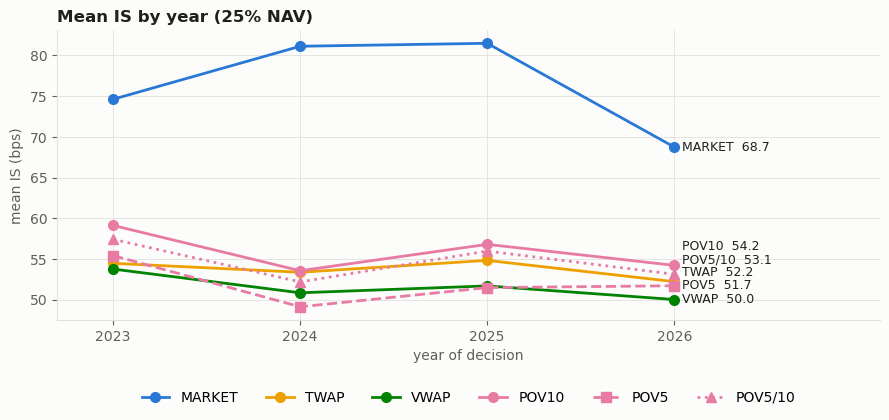

algo          MARKET  TWAP  VWAP  POV10  POV5  POV5/10
bucket  year                                          
1% NAV  2023   49.93 45.64 46.10  49.64 49.23    49.28
        2024   48.21 44.34 42.65  47.07 46.16    46.75
        2025   48.77 44.79 42.98  48.01 47.09    47.79
        2026   45.93 44.79 43.90  45.64 45.14    45.47
5% NAV  2023   57.56 48.56 48.51  53.70 52.47    52.66
        2024   58.39 47.72 45.32  50.31 47.97    49.06
        2025   58.88 48.40 45.73  52.52 50.40    51.40
        2026   52.99 47.34 45.81  49.43 47.91    48.83
10% NAV 2023   63.28 50.71 50.29  56.04 54.22    54.70
        2024   66.01 50.01 47.27  51.69 48.88    50.45
        2025   66.46 50.90 47.77  54.58 51.63    53.51
        2026   58.27 49.17 47.22  51.37 49.41    50.38
25% NAV 2023   74.62 54.46 53.75  59.11 55.40    57.41
        2024   81.13 53.36 50.83  53.55 49.11    52.17
        2025   81.49 54.82 51.68  56.79 51.47    55.96
        2026   68.75 52.21 50.01  54.20 51.70    53.11

In [13]:
by = ex["by_year"]
plots.by_group(by, "year", "25% NAV", "Mean IS by year (25% NAV)", "year of decision"); plt.show()
display(by.set_index(["bucket", "year"]))

## 10. สรุปและข้อจำกัด

ตัวเลขทั้งหมดมาจากการรันด้วย seed ใน `constants.py` (8,000 order, ก.พ. 2023 → พ.ย. 2026, หุ้น 10 ตัวที่ lock, 8 แท่งต่อวันรวม 14:00) รันซ้ำได้ผลเดิมทุกครั้ง

### ข้อค้นพบ
1. **มีต้นทุนพื้นฐานราว 40 bps ที่ algo ไหนก็เลี่ยงไม่ได้** มาจาก ½ spread (≈ 24 bps ภายใต้ค่าสมมติ 1 tick) กับ commission + VAT (≈ 17 bps)

2. **H1 ยืนยัน:** order ยิ่งใหญ่ MARKET ยิ่งแพงกว่าตัวอื่น
   * MARKET แพงกว่า VWAP 4.3 bps ที่ 1% NAV ส่วนนี้**ไม่มีนัยสำคัญ**หลังปรับ Holm
   * ส่วนต่างกว้างขึ้นเป็น 10.7 / 15.5 / **25.1 bps** ที่ 5 / 10 / 25% NAV (25% NAV ≈ 1.9% ของ ADV, 95% CI 21.5–28.6) หรือประมาณ 63,000 บาทต่อ order ขนาด 25M

3. **H2 ยืนยัน และส่วนต่างชัดขึ้นเมื่อรวมแท่ง 14:00:**
   * VWAP ถูกกว่า TWAP 1.0–2.2 bps อย่างมีนัยสำคัญ**ทุกขนาด**
   * สาเหตุคือ TWAP ส่ง 1/8 ของ order ในแท่ง 14:00 ซึ่งมีมูลค่าแค่ราว 2% ของวัน จึงเป็นสัดส่วนใหญ่ของตลาดในแท่งนั้น impact จึงสูง (และที่ 25% NAV ทำครบเพียง 90% ของ order) ส่วน VWAP แทบไม่ส่งในแท่งนี้

4. **H3 ยืนยัน:** std ของ IS ต่อ order ของ TWAP/VWAP ≈ 89 bps เทียบกับ MARKET 50–60 และ POV 49–61

5. **H4 ยืนยันครึ่งเดียว:**
   * **rate ต่ำกว่าถูกกว่าจริง:** ที่ 25% NAV ต้นทุนเรียงเป็น POV5 51.8 < POV5/10 54.6 < POV10 55.8 bps แต่ POV5 ทำครบเพียง 94% ของ order
   * **การแบ่ง rate ตามช่วงเวลาไม่ช่วย:** POV5/10 ไม่ชนะ POV5 ในทุกขนาด (แพงกว่า 0.4–2.8 bps อย่างมีนัยสำคัญ)

6. **VWAP กับ POV5 สูสีกันในเชิงสถิติ:**
   * VWAP ถูกกว่า POV5 เพียง 0.3–3.4 bps ซึ่ง**ไม่มีนัยสำคัญในทุกขนาด** (ที่ 25% NAV: −0.3 bps, CI −2.6 ถึง 2.1)
   * แต่ POV5 แกว่งน้อยกว่ามาก (std 49–61 เทียบกับ 89 bps)
   * ข้อควรระวัง: ส่วนที่ POV5 ทำไม่เสร็จ (6% ที่ 25% NAV) ถูกคิดต้นทุนเฉลี่ยใกล้ศูนย์ จึงทำให้ POV5 ดูดีขึ้นเล็กน้อย

7. **Volume profile เปลี่ยนไปจริงตามเวลา:** เฉลี่ย 3 เดือนแรก (ต้นปี 2023) เทียบกับ 3 เดือนล่าสุด (ปลายปี 2026): แท่ง 17:00 ลดจาก 24% เหลือ 17% ส่วนแท่ง 11:00 เพิ่มจาก 27% เป็น 32% และแท่ง 14:00 จาก 0.0% เป็น 2.0% profile แบบ rolling 21 วันจึงตามการเปลี่ยนแปลงนี้ทัน

8. **ช่วงเวลาของวัน (25% NAV):**
   * MARKET แพงสุดเมื่อแท่งถัดไปบาง: ตัดสินใจตอนปิดแท่ง 13:00 (แท่งถัดไปคือ 14:00) ≈ 106 bps, ตอน 12:00 ≈ 91 bps และตอน 17:00 ≈ 89 bps
   * algo ที่ทยอยส่งอยู่ในช่วงราว 39–65 bps
   * มี order ราว 250 ตัวต่อชั่วโมง ความต่างระดับไม่กี่ bps ระหว่างชั่วโมงจึงยังไม่แน่นอนทางสถิติ

9. **Volatility:** σ ยิ่งสูง ทุก algo ยิ่งแพง MARKET ไวต่อ σ ที่สุด (25% NAV: 65 → 91 bps เทียบกับ VWAP 45 → 59)

10. **Robustness:**
    * **Sensitivity:** VWAP เป็นอันดับ 1 เกือบทุกกรณี ยกเว้นที่ 25% NAV เมื่อ impact Y = 0.5 ซึ่ง POV5 ถูกกว่าเล็กน้อย (46.0 เทียบกับ 46.7 bps) และที่ spread 2 tick ซึ่งทั้งสองตัวเสมอกัน (75.2 bps)
    * **รายปี:** VWAP ถูกที่สุดเกือบทุกปี ข้อยกเว้นคือ 1% NAV ปี 2023 (TWAP ต่ำกว่า 0.5 bps) และ 25% NAV ปี 2024–2025 (POV5 ต่ำกว่า 0.2–1.7 bps) ซึ่งสอดคล้องกับข้อ 6 ว่าที่ขนาดใหญ่ VWAP กับ POV5 สูสีกัน

### ข้อเสนอเชิงปฏิบัติ (ภายใต้สมมติฐานของแบบจำลองนี้)
* **order ≤ ~0.1% ของ ADV:** algo ไหนก็ได้ ส่วนต่างไม่มีนัยสำคัญ
* **order ใหญ่กว่านั้น:** เลือกระหว่าง **VWAP** (ต้นทุนเฉลี่ยต่ำสุด แต่ผลแกว่งมาก) กับ **POV5** (ต้นทุนสูสีกันในเชิงสถิติ แกว่งน้อยกว่าราว 30–45% แต่อาจทำไม่เสร็จภายในวันสำหรับ order ราว 2% ของ ADV ขึ้นไป)
* **ไม่แนะนำ TWAP:** แพ้ VWAP ทุกขนาด
* **ไม่แนะนำ POV5/10:** แพ้ POV5 ทุกขนาด
* **หลีกเลี่ยง MARKET order ก้อนใหญ่** ช่วง 12:00–14:00 และหลังปิดตลาด

### ข้อจำกัด
* **ไม่มี bid/ask และไม่มี order book:** spread เป็นค่าสมมติ ซึ่งกำหนดระดับต้นทุนส่วนใหญ่
* **แท่งรายชั่วโมง:** สมมติว่า child ได้ราคาเท่า VWAP ของแท่งพอดี และ MARKET fill ที่ VWAP ของแท่ง t+1
* **แท่ง 14:00 ที่หายไปจากข้อมูล:** ถือว่าไม่มีการซื้อขาย ถ้าจริงๆ เป็นข้อมูลตกหล่น ต้นทุนของ TWAP ในปี 2023 จะถูกประเมินต่างไปเล็กน้อย
* **Impact model ไม่ได้ calibrate จาก order จริงของเรา:** ใช้ square-root law แบบชั่วคราว ไม่มี permanent impact
* **Look-ahead เล็กน้อย 2 จุด:** cap และ POV ใช้มูลค่าซื้อขายของแท่งที่กำลัง fill และหุ้น 10 ตัวที่ lock เลือกโดยรู้สภาพคล่องตลอดช่วง
* **Order ที่ทำไม่เสร็จ:** ส่วนที่ไม่เสร็จคิดเป็น opportunity cost ที่ค่าเฉลี่ยใกล้ศูนย์ ทำให้ algo ที่ทำไม่ครบ (POV5, TWAP ที่ขนาดใหญ่) ดูดีขึ้นเล็กน้อย
* **ขอบเขตการทดลอง:** ฝั่งขายสมมติว่ามีหุ้นอยู่แล้ว, horizon เดียว (1 วัน) และเฉพาะหุ้นสภาพคล่องสูง